In [1]:
# Cell 1: Import library

import os
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from urllib.parse import quote_plus
from sqlalchemy import create_engine, text
from pathlib import Path

In [2]:
# Cell 2: Connect to MySQL
PROJECT_ROOT = Path.cwd().parent
load_dotenv(PROJECT_ROOT / ".env")
user = os.getenv("MYSQL_USER")
pwd = quote_plus(os.getenv("MYSQL_PASSWORD"))
host = os.getenv("MYSQL_HOST")
port = os.getenv("MYSQL_PORT")
db = os.getenv("MYSQL_DB")
engine = create_engine(f"mysql+pymysql://{user}:{pwd}@{host}:{port}/{db}")

with engine.connect() as conn:
    print("Current database:", conn.execute(text("SELECT DATABASE()")).scalar())

Current database: olist_ecommerce


In [3]:
# Cell 3: Columns of the tables the RFM query will use
for t in ["valid_orders_t", "customers"]:
    print(f"--- {t}")
    display(pd.read_sql(text(f"DESCRIBE {t}"), engine)[["Field", "Type"]])

--- valid_orders_t


,Field,Type
0,order_id,char(32)
1,customer_id,char(32)
2,customer_unique_id,char(32)
3,customer_state,char(2)
4,customer_city,varchar(100)
5,order_status,varchar(20)
6,order_purchase_timestamp,datetime
7,order_delivered_customer_date,datetime
8,order_estimated_delivery_date,datetime
9,revenue,"decimal(32,2)"


--- customers


,Field,Type
0,customer_id,char(32)
1,customer_unique_id,char(32)
2,customer_zip_code_prefix,int
3,customer_city,varchar(100)
4,customer_state,char(2)


In [4]:
# Cell 4: One row per customer (customer_unique_id) from valid sales
q = """
SELECT customer_unique_id,
       MIN(order_purchase_timestamp) AS first_purchase,
       MAX(order_purchase_timestamp) AS last_purchase,
       COUNT(*)                      AS frequency,
       SUM(revenue)                  AS monetary
FROM valid_orders_t
GROUP BY customer_unique_id
"""

rfm = pd.read_sql(text(q), engine, parse_dates=["first_purchase", "last_purchase"])
rfm["monetary"] = rfm["monetary"].astype(float)
rfm = rfm.sort_values("customer_unique_id").reset_index(drop=True)   # fixed order, so tie-breaking is repeatable
print(rfm.shape)
rfm.head()

(94982, 5)


,customer_unique_id,first_purchase,last_purchase,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,2018-05-10 10:56:27,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,2018-05-07 11:11:27,1,27.19
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,2017-03-10 21:05:03,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,2017-10-12 20:29:41,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,2017-11-14 19:45:42,1,196.89


In [5]:
# Cell 5: recency (days before the refrence date) and checks against notebook 6
ref_date = rfm["last_purchase"].max().normalize() + pd.Timedelta(days=1)
rfm["recency_days"] = (ref_date - rfm["last_purchase"]).dt.total_seconds() / 86400
print("Refrence date:", ref_date.date())

freq_counts = rfm["frequency"].value_counts().sort_index()
checks = {
    "customers = 94982":            len(rfm) == 94982,
    "orders = 98198":               int(rfm["frequency"].sum()) == 98198,
    "revenue = 15738221.95":        round(rfm["monetary"].sum(), 2) == 15738221.95,
    "repeat customers = 2887":      int((rfm["frequency"] > 1).sum()) == 2887,
    "1 order = 92095 customers":    int(freq_counts.get(1, 0)) == 92095,
}

for k, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", k)
print(freq_counts)

Refrence date: 2018-09-04
PASS - customers = 94982
PASS - orders = 98198
PASS - revenue = 15738221.95
PASS - repeat customers = 2887
PASS - 1 order = 92095 customers
frequency
1     92095
2      2651
3       188
4        29
5         9
6         5
7         3
9         1
16        1
Name: count, dtype: int64


In [6]:
# Cell 6: Scores: R and M use quintiles (5 = best); F uses fixed bands because 97% of customers have 1 order
labels = [1, 2, 3, 4, 5]
rfm["R"] = pd.qcut(rfm["recency_days"].rank(method="first", ascending=False), 5, labels=labels).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=labels).astype(int)
rfm["F"] = np.select([rfm["frequency"] == 1, rfm["frequency"] == 2], [1, 2], default=3)

print("R score sizes:", rfm["R"].value_counts().sort_index().tolist())
print("M score sizes:", rfm["M"].value_counts().sort_index().tolist())
print("F score sizes:", rfm["F"].value_counts().sort_index().tolist())
print(rfm.groupby("R")["recency_days"].agg(["min", "max"]).round(0))
print(rfm.groupby("M")["monetary"].agg(["min", "max"]).round(2))

R score sizes: [18997, 18996, 18996, 18996, 18997]
M score sizes: [18997, 18996, 18996, 18996, 18997]
F score sizes: [92095, 2651, 236]
     min    max
R              
1  389.0  729.0
2  273.0  389.0
3  182.0  273.0
4   98.0  182.0
5    1.0   98.0
      min       max
M                  
1    9.59     55.36
2   55.36     87.51
3   87.51    133.05
4  133.05    209.12
5  209.12  13664.08


In [7]:
# Cell 7: segment (first matching rule wins) and segment summary
conds = [
    (rfm["F"] >= 2) & (rfm["R"] >= 4),     # repeat buyers who ordered recently
    (rfm["F"] >= 2),                       # repeat buyers who have gone quiet
    (rfm["R"] >= 4) & (rfm["M"] >= 4),     # one order, recent, high spend
    (rfm["R"] >= 4),                       # one order, recent
    (rfm["M"] >= 4),                       # one order, not recent, high spend
]

names = ["Champions", "Repeat but lapsing", "Recent high spenders", "Recent customers", "Lapsed high spenders"]
rfm["segment"] = np.select(conds, names, default='Lapsed low spenders')

seg = rfm.groupby("segment").agg(customers = ("customer_unique_id", "size"),
                                 revenue=("monetary", "sum"),
                                 avg_recency_days=("recency_days", "mean"),
                                 avg_orders=("frequency", "mean"),
                                 avg_spend=("monetary", "mean"))

seg["customer_share_pct"] = seg["customers"] / seg["customers"].sum() * 100
seg["revenue_share_pct"] = seg["revenue"] / seg["revenue"].sum() * 100
seg = seg.sort_values("revenue", ascending=False).round(2)
display(seg)


print("PASS" if seg["customers"].sum() == 94982 else "FAIL", "- segments cover 94982 customers")
print("PASS" if round(seg["revenue"].sum(), 2) == 15738221.95 else "FAIL", "- segment revenue = 15738221.95")

,customers,revenue,avg_recency_days,avg_orders,avg_spend,customer_share_pct,revenue_share_pct
segment,,,,,,,
Lapsed high spenders,21050,6306060.04,341.76,1.00,299.58,22.16,40.07
Recent high spenders,14648,4438472.70,97.06,1.00,303.01,15.42,28.20
Lapsed low spenders,34291,2487823.25,343.40,1.00,72.55,36.10,15.81
Recent customers,22106,1615481.00,95.01,1.00,73.08,23.27,10.26
Repeat but lapsing,1648,491992.03,326.59,2.08,298.54,1.74,3.13
Champions,1239,398392.93,94.12,2.16,321.54,1.30,2.53


PASS - segments cover 94982 customers
PASS - segment revenue = 15738221.95


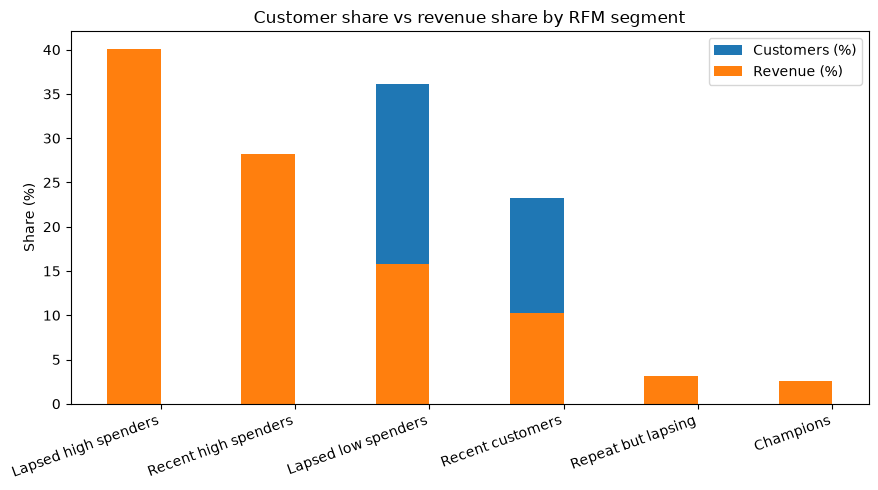

In [8]:
# Cell 8: customer share vs revenue share by segment
import matplotlib.pyplot as plt

order = seg.index.tolist()    
x = np.arange(len(order))
w = 0.4
fig, ax = plt.subplots(figsize = (9, 5))
ax.bar(x - w / 2, seg["customer_share_pct"], w, label = "Customers (%)")
ax.bar(x + - w / 2, seg["revenue_share_pct"], w, label = "Revenue (%)")
ax.set_xticks(x)
ax.set_xticklabels(order, rotation = 20, ha = "right")
ax.set_ylabel("Share (%)")
ax.set_title("Customer share vs revenue share by RFM segment")
ax.legend()
plt.tight_layout()
plt.show()


## RFM findings

**Data:** 94,982 customers (by customer_unique_id) from valid sales, R$15,738,221.95 in total. Reference date 2018-09-04 (the day after the last purchase). All totals reconcile with notebook 6.

**Scoring:** Recency and Monetary are scored in quintiles (5 = best). Frequency uses fixed bands (1, 2, 3+ orders) because 92,095 customers (97%) ordered once, so quintiles would be mostly ties. Segments are rule-based and are my own definitions, not a standard.

### Segments
| Segment | Customers | Customer share | Revenue share | Avg spend |
|---|---|---|---|---|
| Lapsed high spenders | 21,050 | 22.16% | 40.07% | R$299.58 |
| Recent high spenders | 14,648 | 15.42% | 28.20% | R$303.01 |
| Lapsed low spenders | 34,291 | 36.10% | 15.81% | R$72.55 |
| Recent customers | 22,106 | 23.27% | 10.26% | R$73.08 |
| Repeat but lapsing | 1,648 | 1.74% | 3.13% | R$298.54 |
| Champions | 1,239 | 1.30% | 2.53% | R$321.54 |

### Findings
- **Spending matters more than recency.** The two high-spender groups (one order, top 40% by spend, i.e. above about R$133) are 37.6% of customers and bring 68.3% of revenue. The two low-spender groups are 59.4% of customers and bring 26.1%.
- **Most of the valuable one-time buyers have not come back.** Lapsed high spenders (21,050 customers, 40.1% of revenue) last ordered about 342 days before the reference date on average.
- **Repeat buyers are rare.** Champions and Repeat but lapsing together are 2,887 customers (3.04%) and bring 5.66% of revenue. Their average spend (R$299 to R$322) is about the same as one-time high spenders (R$300 to R$303), so repeat buying does not make a customer much more valuable in this data. What stands out is how few customers return at all.
- **Retention is the largest gap.** 96.96% of customers bought once, so even a small rise in repeat purchases among the 35,698 high spenders would affect a large share of revenue.

### Limits
- "Recent" means a last order within about 182 days (R of 4 or 5) of the dataset end; "high spender" means a spend above about R$133 (M of 4 or 5). Other cutoffs would move customers between segments.
- Monetary is the order revenue defined by the valid-sales rule, summed over all of a customer's orders.
- The data ends in September 2018, so a customer marked "lapsed" may simply not have had time to return in this data.